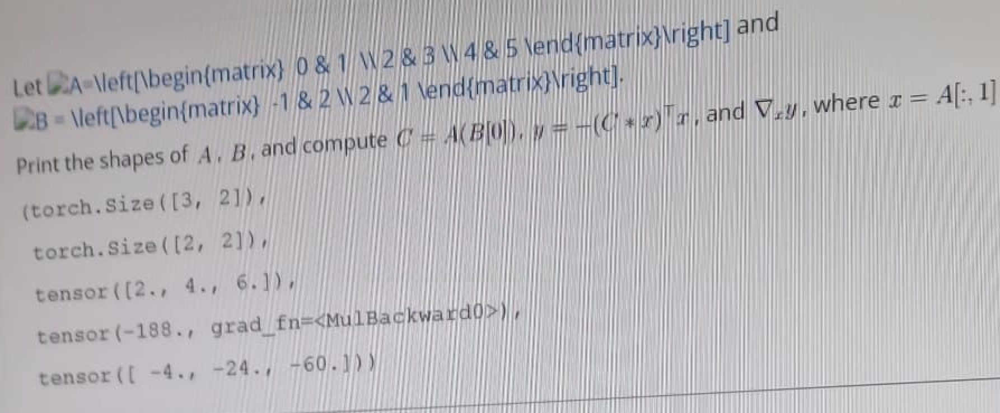

In [1]:
import torch

# 1. Define Matrices A and B
# Use floats to support gradient calculation
A = torch.tensor([[0.0, 1.0], [2.0, 3.0], [4.0, 5.0]])
B = torch.tensor([[-1.0, 2.0], [2.0, 1.0]])

# 2. Print shapes
print(A.shape)
print(B.shape)

C = torch.matmul(A, B[0])
print(C)

# 4. Define x and enable gradients
# We create x from the 2nd column of A.
# To compute grad_x y specifically (treating C as constant),
# we detach x and enable gradient tracking.
x = A[:, 1].clone().detach()
x.requires_grad = True

# 5. Compute y = -(C * x)^T x
# (C * x) is element-wise multiplication
# The result is dot-producted with x
y = -torch.dot(C * x, x)
print(y)

# 6. Compute gradient
y.backward()
print(x.grad)

torch.Size([3, 2])
torch.Size([2, 2])
tensor([2., 4., 6.])
tensor(-188., grad_fn=<NegBackward0>)
tensor([ -4., -24., -60.])


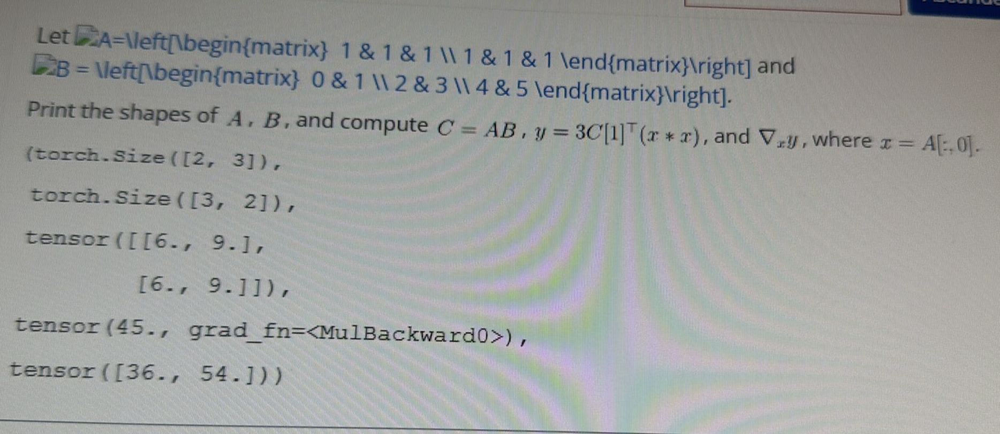

In [2]:
# 1. Define Matrices A and B
# Use floats to support gradient calculation
A = torch.tensor([[1.0, 1.0, 1.0], [1.0, 1.0, 1.0]])

B = torch.tensor([[0.0, 1.0], [2.0, 3.0], [4.0, 5.0]])

# 2. Print shapes of A and B
print(A.shape)
print(B.shape)

# 3. Compute C = AB (Matrix Multiplication)
C = torch.matmul(A, B)
print(C)

# 4. Define x based on A[:, 0]
# We extract the first column of A.
# To compute gradients w.r.t x specifically, we clone/detach it
# and enable requires_grad.
x = A[:, 0].clone().detach()
x.requires_grad = True

# 5. Compute y = 3 * C[1]^T * (x * x)
# C[1] is the second row of C: [6., 9.]
# (x * x) is element-wise squaring
# The transpose notation T implies a dot product here between the vectors
y = 3 * torch.dot(C[1], x * x)
print(y)

# 6. Compute gradient of y with respect to x
y.backward()
print(x.grad)

torch.Size([2, 3])
torch.Size([3, 2])
tensor([[6., 9.],
        [6., 9.]])
tensor(45., grad_fn=<MulBackward0>)
tensor([36., 54.])


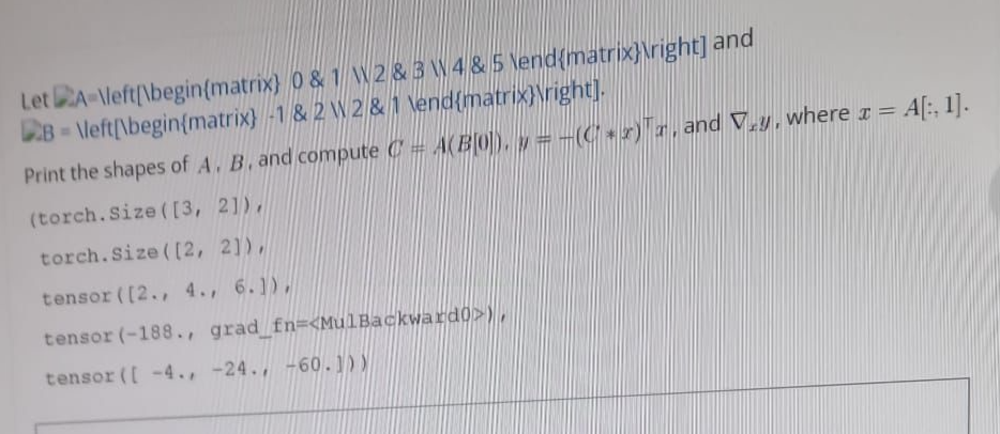

In [3]:
# 1. Define Matrices A and B
# Use floats to support gradient calculation
A = torch.tensor([[0.0, 1.0], [2.0, 3.0], [4.0, 5.0]])

B = torch.tensor([[-1.0, 2.0], [2.0, 1.0]])

# 2. Print shapes of A and B
print(A.shape)
print(B.shape)

# 3. Compute C = AB[0] (Matrix Multiplication)
C = torch.matmul(A, B[0])
print(C)

# 4. Define x based on A[:, 1]
# We extract the second column of A.
# To compute gradients w.r.t x specifically, we clone/detach it
# and enable requires_grad.
x = A[:, 1].clone().detach()
x.requires_grad = True

# 5. Compute y = 3 * C[1]^T * (x * x)
# C[1] is the second row of C: [6., 9.]
# (x * x) is element-wise squaring
# The transpose notation T implies a dot product here between the vectors
y = -torch.dot(C * x, x)
print(y)

# 6. Compute gradient of y with respect to x
y.backward()
print(x.grad)

torch.Size([3, 2])
torch.Size([2, 2])
tensor([2., 4., 6.])
tensor(-188., grad_fn=<NegBackward0>)
tensor([ -4., -24., -60.])


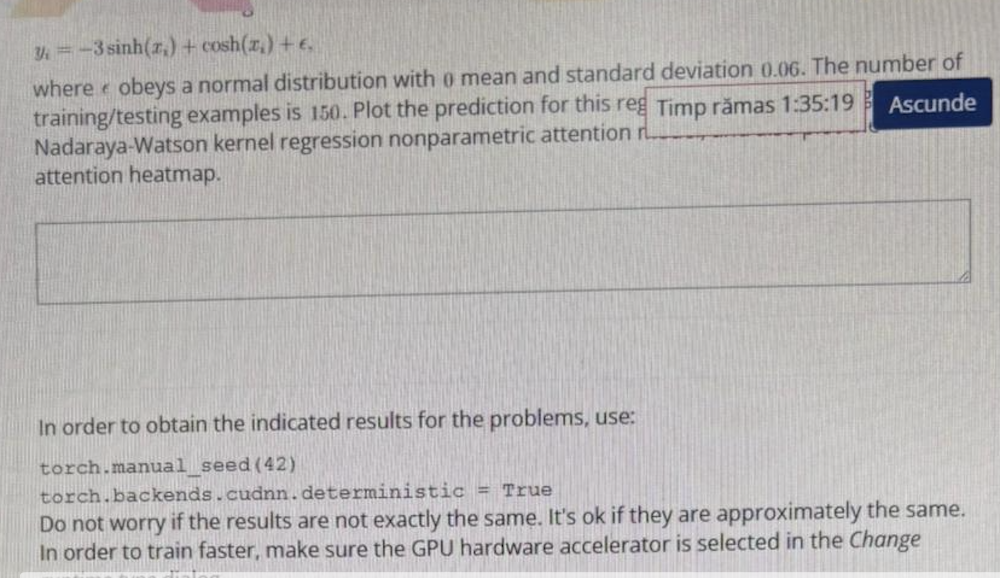

In [4]:
import torch
from torch import nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import math
import os
import requests
import zipfile
import collections

torch.manual_seed(42)
torch.backends.cudnn.deterministic = True

In [5]:
n_train = 150  # No. of training examples
x_train, _ = torch.sort(torch.rand(n_train) * 5)  # Training inputs

In [6]:
def f(x):
    return (-3) * torch.sinh(x) + 3 * torch.cosh(x)


y_train = f(x_train) + torch.normal(0.0, 0.08, (n_train,))  # Training outputs

x_test = torch.arange(
    0, 7.5, 0.05
)  # avem 100 de exemple deci generam de la 0 la 5 cu step de 0.05

y_truth = f(x_test)  # Ground-truth outputs for the testing examples
n_test = len(x_test)  # No. of testing examples

n_test

150

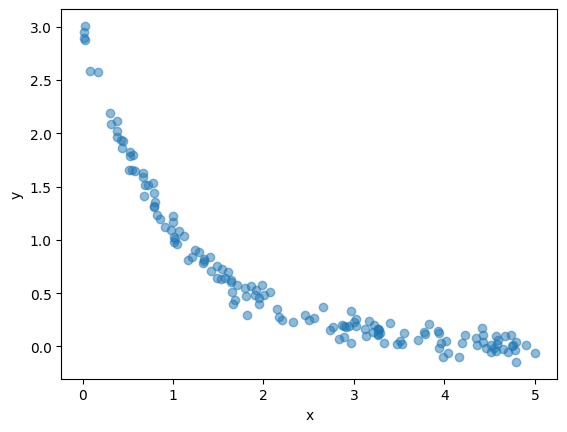

In [7]:
def plot_training_data():
    plt.xlabel("x")
    plt.ylabel("y")
    plt.plot(x_train, y_train, "o", alpha=0.5)


plot_training_data()

In [8]:
def plot_kernel_reg(y_hat):
    plt.plot(x_test, y_truth, label="Truth")
    plt.plot(x_test, y_hat, label="Pred")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.xlim([0, 5])
    plt.ylim(
        [-4, 15]
    )  # aici schimbat din -1 in -4 si din 5 in 15 de pe functia de dinainte
    plt.legend()
    plt.plot(x_train, y_train, "o", alpha=0.5)

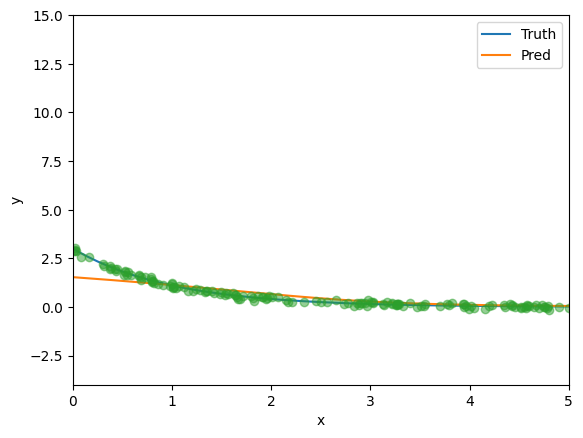

In [9]:
# Shape of `X_repeat` is: (`n_test`, `n_train`), where each row contains the
# same testing inputs (i.e., same queries)
X_repeat = x_test.repeat_interleave(n_train).reshape((-1, n_train))
# Note that `x_train` contains the keys. Shape of `attention_weights` is:
# (`n_test`, `n_train`), where each row contains attention weights to be
# assigned among the values (`y_train`), given each query
attention_weights = F.softmax(-((X_repeat - x_train) ** 2) / 2, dim=1)
# Each element of `y_hat` is a weighted average of values, where weights are
# attention weights
y_hat = torch.matmul(attention_weights, y_train)
plot_kernel_reg(y_hat)

In [10]:
def show_heatmaps(
    matrices, xlabel, ylabel, titles=None, figsize=(2.5, 2.5), cmap="Reds"
):
    """Show heatmaps of matrices."""
    num_rows, num_cols = matrices.shape[0], matrices.shape[1]
    fig, axes = plt.subplots(
        num_rows, num_cols, figsize=figsize, sharex=True, sharey=True, squeeze=False
    )
    for i, (row_axes, row_matrices) in enumerate(zip(axes, matrices)):
        for j, (ax, matrix) in enumerate(zip(row_axes, row_matrices)):
            pcm = ax.imshow(matrix.detach().numpy(), cmap=cmap)
            if i == num_rows - 1:
                ax.set_xlabel(xlabel)
            if j == 0:
                ax.set_ylabel(ylabel)
            if titles:
                ax.set_title(titles[j])
    fig.colorbar(pcm, ax=axes, shrink=0.6)

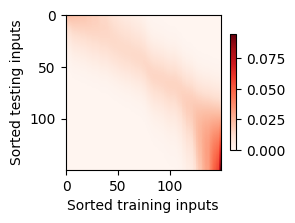

In [11]:
show_heatmaps(
    attention_weights.unsqueeze(0).unsqueeze(0),
    xlabel="Sorted training inputs",
    ylabel="Sorted testing inputs",
)

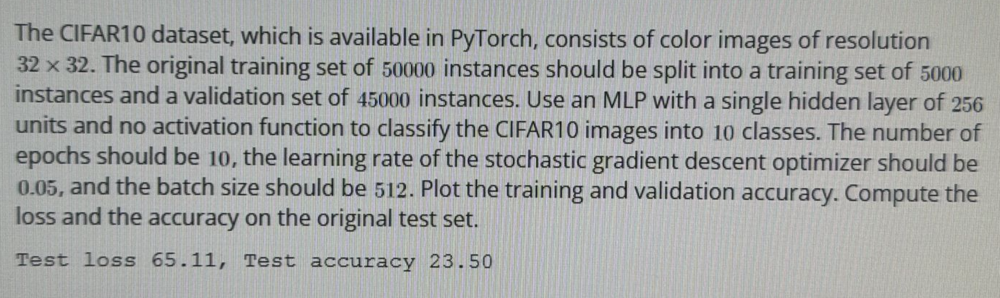

In [12]:
import torchvision
from torchvision import transforms
import torch
import matplotlib.pyplot as plt
import numpy as np
from torch import nn

In [13]:
def load_data_CIFAR10(batch_size, resize=None):
    """Download the Fashion-MNIST dataset and then load it into memory."""
    trans = [transforms.ToTensor()]
    if resize:
        trans.insert(0, transforms.Resize(resize))
    trans = transforms.Compose(trans)
    CIFAR10_train = torchvision.datasets.CIFAR10(
        root="../data", train=True, transform=trans, download=True
    )
    CIFAR10_test = torchvision.datasets.CIFAR10(
        root="../data", train=False, transform=trans, download=True
    )
    CIFAR10_train, CIFAR10_val = torch.utils.data.random_split(
        CIFAR10_train, [5000, 45000], generator=torch.Generator().manual_seed(42)
    )
    return (
        torch.utils.data.DataLoader(
            CIFAR10_train, batch_size, shuffle=True, num_workers=2
        ),
        torch.utils.data.DataLoader(
            CIFAR10_val, batch_size, shuffle=False, num_workers=2
        ),
        torch.utils.data.DataLoader(
            CIFAR10_test, batch_size, shuffle=False, num_workers=2
        ),
    )

In [14]:
batch_size = 512

train_iter, val_iter, test_iter = load_data_CIFAR10(batch_size)

  5%|▌         | 9.01M/170M [00:03<01:09, 2.33MB/s]


KeyboardInterrupt: 

In [ ]:
num_epochs = 10
lr = 0.05

In [ ]:
net = nn.Sequential(
    nn.Flatten(),
    nn.Linear(3072, 1024),  # 3 * 32 * 32 input, 1024 hidden units output
    nn.Linear(1024, 10),  # 1024 in, 10 classes out
)

In [ ]:
def init_weights(m):
    if type(m) == nn.Linear:
        nn.init.normal_(m.weight, std=0.01)


net.apply(init_weights)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=3072, out_features=1024, bias=True)
  (2): Linear(in_features=1024, out_features=10, bias=True)
)

In [ ]:
loss = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(net.parameters(), lr=lr)

In [ ]:
def evaluate_accuracy(net, data_iter):
    """Compute the accuracy for a model on a dataset."""
    net.eval()  # Set the model to evaluation mode

    total_loss = 0
    total_hits = 0
    total_samples = 0
    with torch.no_grad():
        for X, y in data_iter:
            y_hat = net(X)
            l = loss(y_hat, y)
            total_loss += float(l)
            total_hits += sum(net(X).argmax(axis=1).type(y.dtype) == y)
            total_samples += y.numel()
    return float(total_loss) / len(data_iter), float(total_hits) / total_samples * 100

In [ ]:
def train_epoch(net, train_iter, loss, optimizer):
    # Set the model to training mode
    net.train()
    # Sum of training loss, sum of training correct predictions, no. of examples
    total_loss = 0
    total_hits = 0
    total_samples = 0
    for X, y in train_iter:
        # Compute gradients and update parameters
        y_hat = net(X)
        l = loss(y_hat, y)
        # Using PyTorch built-in optimizer & loss criterion
        optimizer.zero_grad()
        l.backward()
        optimizer.step()
        total_loss += float(l)
        total_hits += sum(y_hat.argmax(axis=1).type(y.dtype) == y)
        total_samples += y.numel()
    # Return training loss and training accuracy
    return float(total_loss) / len(train_iter), float(total_hits) / total_samples * 100

In [ ]:
def train(net, train_iter, val_iter, loss, num_epochs, optimizer):
    """Train a model."""
    train_loss_all = []
    train_acc_all = []
    val_loss_all = []
    val_acc_all = []
    for epoch in range(num_epochs):
        train_loss, train_acc = train_epoch(net, train_iter, loss, optimizer)
        train_loss_all.append(train_loss)
        train_acc_all.append(train_acc)
        val_loss, val_acc = evaluate_accuracy(net, val_iter)
        val_loss_all.append(val_loss)
        val_acc_all.append(val_acc)
        print(
            f"Epoch {epoch + 1}, Train loss {train_loss:.2f}, Train accuracy {train_acc:.2f}, Validation loss {val_loss:.2f}, Validation accuracy {val_acc:.2f}"
        )

    return train_loss_all, train_acc_all, val_loss_all, val_acc_all

In [ ]:
train_loss_all, train_acc_all, val_loss_all, val_acc_all = train(
    net, train_iter, val_iter, loss, num_epochs, optimizer
)

/tmp/ipython-input-3329971113.py:16: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  total_loss += float(l)


Epoch 1, Train loss 2.27, Train accuracy 13.40, Validation loss 2.23, Validation accuracy 19.70
Epoch 2, Train loss 2.19, Train accuracy 21.26, Validation loss 2.16, Validation accuracy 24.68
Epoch 3, Train loss 2.13, Train accuracy 25.78, Validation loss 2.12, Validation accuracy 25.05
Epoch 4, Train loss 2.09, Train accuracy 26.58, Validation loss 2.07, Validation accuracy 28.90
Epoch 5, Train loss 2.05, Train accuracy 27.44, Validation loss 2.04, Validation accuracy 28.80
Epoch 6, Train loss 2.02, Train accuracy 30.46, Validation loss 2.03, Validation accuracy 29.33
Epoch 7, Train loss 2.00, Train accuracy 29.58, Validation loss 1.99, Validation accuracy 31.37
Epoch 8, Train loss 1.98, Train accuracy 31.96, Validation loss 1.99, Validation accuracy 27.94
Epoch 9, Train loss 1.96, Train accuracy 31.58, Validation loss 1.96, Validation accuracy 31.61
Epoch 10, Train loss 1.95, Train accuracy 32.84, Validation loss 1.96, Validation accuracy 31.15


In [ ]:
test_loss, test_acc = evaluate_accuracy(net, test_iter)
print(f"Test loss {test_loss:.2f}, Test accuracy {test_acc:.2f}")

Test loss 1.96, Test accuracy 31.24


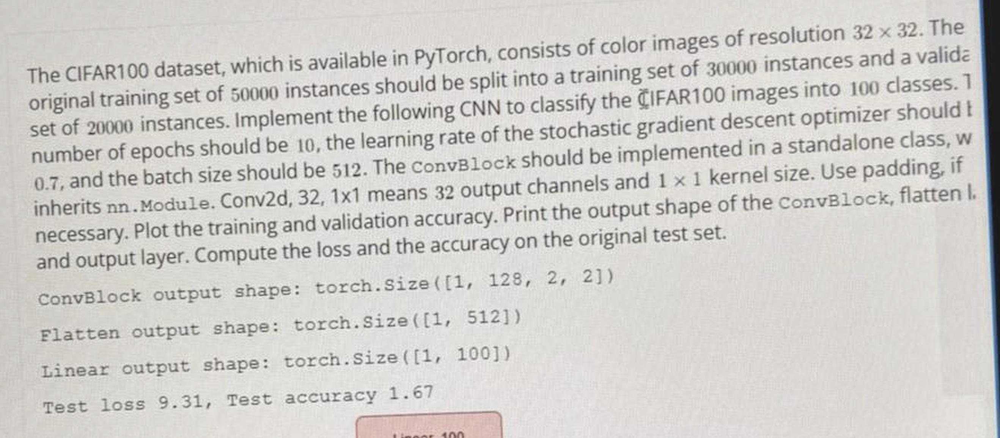

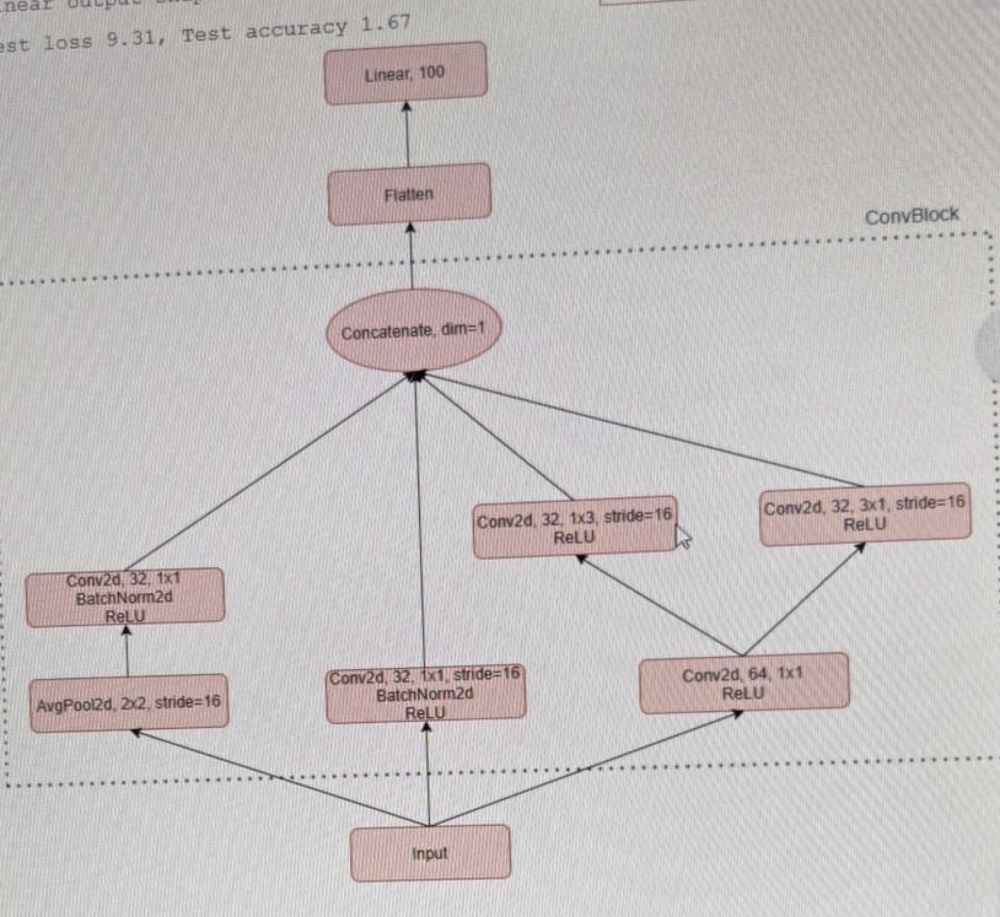

In [ ]:
import torch
import torch.nn as nn


class ConvolutionalBlock(nn.Module):
    def __init__(self, in_channels):
        super(ConvolutionalBlock, self).__init__()

        # --- Branch 1: AvgPool -> 1x1 Conv -> BN -> ReLU ---
        # Input: [B, C, 32, 32] -> AvgPool -> [B, C, 2, 2]
        self.avgpool = nn.AvgPool2d(kernel_size=2, stride=16)
        self.conv1x1_1 = nn.Conv2d(in_channels, 32, kernel_size=1)
        self.bn1 = nn.BatchNorm2d(32)  # Unique BN for branch 1
        self.relu = nn.ReLU()

        # --- Branch 2: 1x1 Conv (stride 16) -> BN -> ReLU ---
        # Input: [B, C, 32, 32] -> Conv(s16) -> [B, 32, 2, 2]
        self.conv1x1_2 = nn.Conv2d(in_channels, 32, kernel_size=1, stride=16)
        self.bn2 = nn.BatchNorm2d(32)  # Unique BN for branch 2

        # --- Branch 3 (Stem): 1x1 Conv -> ReLU ---
        # Input: [B, C, 32, 32] -> Conv -> [B, 64, 32, 32]
        self.conv1x1_3 = nn.Conv2d(in_channels, 64, kernel_size=1)

        # --- Branch 3a: 1x3 Conv (stride 16) -> ReLU ---
        # Input: [B, 64, 32, 32] -> Conv(s16) -> [B, 32, 2, 2]
        self.conv1x3 = nn.Conv2d(64, 32, kernel_size=(1, 3), padding=(0, 1), stride=16)

        # --- Branch 3b: 3x1 Conv (stride 16) -> ReLU ---
        # Input: [B, 64, 32, 32] -> Conv(s16) -> [B, 32, 2, 2]
        self.conv3x1 = nn.Conv2d(64, 32, kernel_size=(3, 1), padding=(1, 0), stride=16)

    def forward(self, x):
        # Branch 1 Flow
        branch1 = self.avgpool(x)
        branch1 = self.conv1x1_1(branch1)
        branch1 = self.bn1(branch1)
        branch1 = self.relu(branch1)

        # Branch 2 Flow
        branch2 = self.conv1x1_2(x)
        branch2 = self.bn2(branch2)
        branch2 = self.relu(branch2)

        # Branch 3 Flow
        branch3_stem = self.conv1x1_3(x)
        branch3_stem = self.relu(branch3_stem)

        # Branch 3a (from stem)
        branch3_1 = self.conv1x3(branch3_stem)
        branch3_1 = self.relu(branch3_1)

        # Branch 3b (from stem)
        branch3_2 = self.conv3x1(branch3_stem)
        branch3_2 = self.relu(branch3_2)

        # Concatenate all 4 outputs
        # Shapes: [B, 32, 2, 2] * 4 -> [B, 128, 2, 2]
        out = torch.cat([branch1, branch2, branch3_1, branch3_2], dim=1)

        return out

In [ ]:
# modelul complet

net = nn.Sequential(
    ConvolutionalBlock(3),  # 3 input channels rgb image
    nn.Flatten(),
    nn.Linear(512, 100),  # -> out channels * height * width si 10 clase
)

net

Sequential(
  (0): ConvolutionalBlock(
    (avgpool): AvgPool2d(kernel_size=2, stride=16, padding=0)
    (conv1x1_1): Conv2d(3, 32, kernel_size=(1, 1), stride=(1, 1))
    (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU()
    (conv1x1_2): Conv2d(3, 32, kernel_size=(1, 1), stride=(16, 16))
    (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (conv1x1_3): Conv2d(3, 64, kernel_size=(1, 1), stride=(1, 1))
    (conv1x3): Conv2d(64, 32, kernel_size=(1, 3), stride=(16, 16), padding=(0, 1))
    (conv3x1): Conv2d(64, 32, kernel_size=(3, 1), stride=(16, 16), padding=(1, 0))
  )
  (1): Flatten(start_dim=1, end_dim=-1)
  (2): Linear(in_features=512, out_features=100, bias=True)
)

In [ ]:
X = torch.randn(1, 3, 32, 32)

for layer in net:
    X = layer(X)
    print(layer.__class__.__name__, " output shape : \t", X.shape)

ConvolutionalBlock  output shape : 	 torch.Size([1, 128, 2, 2])
Flatten  output shape : 	 torch.Size([1, 512])
Linear  output shape : 	 torch.Size([1, 100])


In [ ]:
def load_data_CIFAR100(batch_size, resize=None):
    """Download the Fashion-MNIST dataset and then load it into memory."""
    trans = [transforms.ToTensor()]
    if resize:
        trans.insert(0, transforms.Resize(resize))
    trans = transforms.Compose(trans)
    CIFAR100_train = torchvision.datasets.CIFAR100(
        root="../data", train=True, transform=trans, download=True
    )
    CIFAR100_test = torchvision.datasets.CIFAR100(
        root="../data", train=False, transform=trans, download=True
    )
    CIFAR100_train, CIFAR100_val = torch.utils.data.random_split(
        CIFAR100_train, [8000, 42000], generator=torch.Generator().manual_seed(42)
    )
    return (
        torch.utils.data.DataLoader(
            CIFAR100_train, batch_size, shuffle=True, num_workers=2
        ),
        torch.utils.data.DataLoader(
            CIFAR100_val, batch_size, shuffle=False, num_workers=2
        ),
        torch.utils.data.DataLoader(
            CIFAR100_test, batch_size, shuffle=False, num_workers=2
        ),
    )

In [ ]:
def evaluate_accuracy(net, data_iter, loss, device):
    """Compute the accuracy for a model on a dataset."""
    net.eval()  # Set the model to evaluation mode

    total_loss = 0
    total_hits = 0
    total_samples = 0
    with torch.no_grad():
        for X, y in data_iter:
            X, y = X.to(device), y.to(device)
            y_hat = net(X)
            l = loss(y_hat, y)
            total_loss += float(l)
            total_hits += sum(net(X).argmax(axis=1).type(y.dtype) == y)
            total_samples += y.numel()
    return float(total_loss) / len(data_iter), float(total_hits) / total_samples * 100

In [ ]:
def train_epoch(net, train_iter, loss, optimizer, device):
    # Set the model to training mode
    net.train()
    # Sum of training loss, sum of training correct predictions, no. of examples
    total_loss = 0
    total_hits = 0
    total_samples = 0
    for X, y in train_iter:
        # Compute gradients and update parameters
        X, y = X.to(device), y.to(device)
        y_hat = net(X)
        l = loss(y_hat, y)
        # Using PyTorch built-in optimizer & loss criterion
        optimizer.zero_grad()
        l.backward()
        optimizer.step()
        total_loss += float(l)
        total_hits += sum(y_hat.argmax(axis=1).type(y.dtype) == y)
        total_samples += y.numel()
    # Return training loss and training accuracy
    return float(total_loss) / len(train_iter), float(total_hits) / total_samples * 100

In [ ]:
def train(net, train_iter, val_iter, test_iter, num_epochs, lr, device):
    """Train a model."""
    train_loss_all = []
    train_acc_all = []
    val_loss_all = []
    val_acc_all = []

    def init_weights(m):
        if type(m) == nn.Linear or type(m) == nn.Conv2d:
            nn.init.xavier_uniform_(m.weight)

    net.apply(init_weights)
    print("Training on", device)
    net.to(device)
    optimizer = torch.optim.SGD(net.parameters(), lr=lr)
    loss = nn.CrossEntropyLoss()
    for epoch in range(num_epochs):
        train_loss, train_acc = train_epoch(net, train_iter, loss, optimizer, device)
        train_loss_all.append(train_loss)
        train_acc_all.append(train_acc)
        val_loss, val_acc = evaluate_accuracy(net, val_iter, loss, device)
        val_loss_all.append(val_loss)
        val_acc_all.append(val_acc)
        print(
            f"Epoch {epoch + 1}, Train loss {train_loss:.2f}, Train accuracy {train_acc:.2f}, Validation loss {val_loss:.2f}, Validation accuracy {val_acc:.2f}"
        )
    test_loss, test_acc = evaluate_accuracy(net, test_iter, loss, device)
    print(f"Test loss {test_loss:.2f}, Test accuracy {test_acc:.2f}")

    return train_loss_all, train_acc_all, val_loss_all, val_acc_all

In [ ]:
def try_gpu(i=0):
    """Return gpu(i) if exists, otherwise return cpu()."""
    if torch.cuda.device_count() >= i + 1:
        return torch.device(f"cuda:{i}")
    return torch.device("cpu")

In [ ]:
def plot_loss(train_loss_all, val_loss_all):
    epochs = range(1, len(train_loss_all) + 1)
    plt.plot(epochs, train_loss_all, "bo", label="Training loss")
    plt.plot(epochs, val_loss_all, "b", label="Validation loss")
    plt.title("Training and validation loss")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()

In [ ]:
def plot_accuracy(train_acc_all, val_acc_all):
    epochs = range(1, len(train_acc_all) + 1)
    plt.plot(epochs, train_acc_all, "bo", label="Training acc")
    plt.plot(epochs, val_acc_all, "b", label="Validation acc")
    plt.title("Training and validation accuracy")
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.show()

In [ ]:
batch_size, lr, num_epochs = 256, 0.05, 5
train_iter, val_iter, test_iter = load_data_CIFAR100(batch_size)
train_loss_all, train_acc_all, val_loss_all, val_acc_all = train(
    net, train_iter, val_iter, test_iter, num_epochs, lr, try_gpu()
)  # 2 min

100%|██████████| 169M/169M [00:03<00:00, 43.3MB/s]


Training on cuda:0
Epoch 1, Train loss 4.64, Train accuracy 1.84, Validation loss 4.56, Validation accuracy 2.24
Epoch 2, Train loss 4.45, Train accuracy 3.66, Validation loss 4.43, Validation accuracy 3.86
Epoch 3, Train loss 4.35, Train accuracy 5.11, Validation loss 4.35, Validation accuracy 4.50
Epoch 4, Train loss 4.27, Train accuracy 6.06, Validation loss 4.29, Validation accuracy 5.44
Epoch 5, Train loss 4.21, Train accuracy 6.60, Validation loss 4.25, Validation accuracy 5.92
Test loss 4.26, Test accuracy 5.82


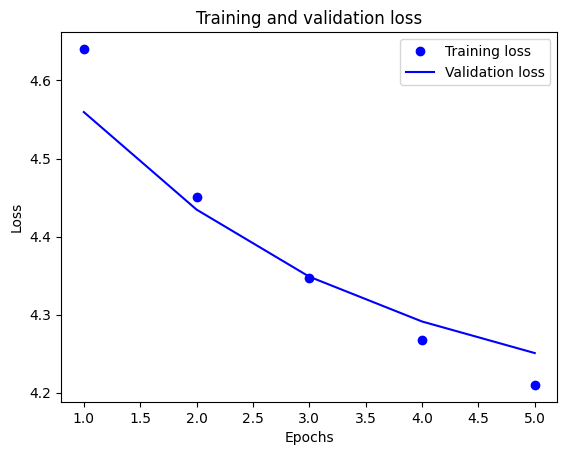

In [ ]:
plot_loss(train_loss_all, val_loss_all)

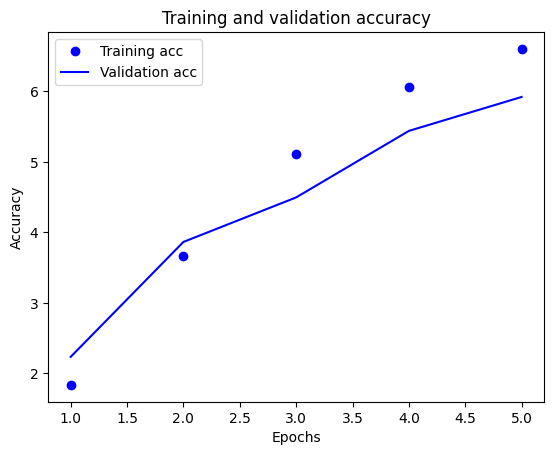

In [ ]:
plot_accuracy(train_acc_all, val_acc_all)

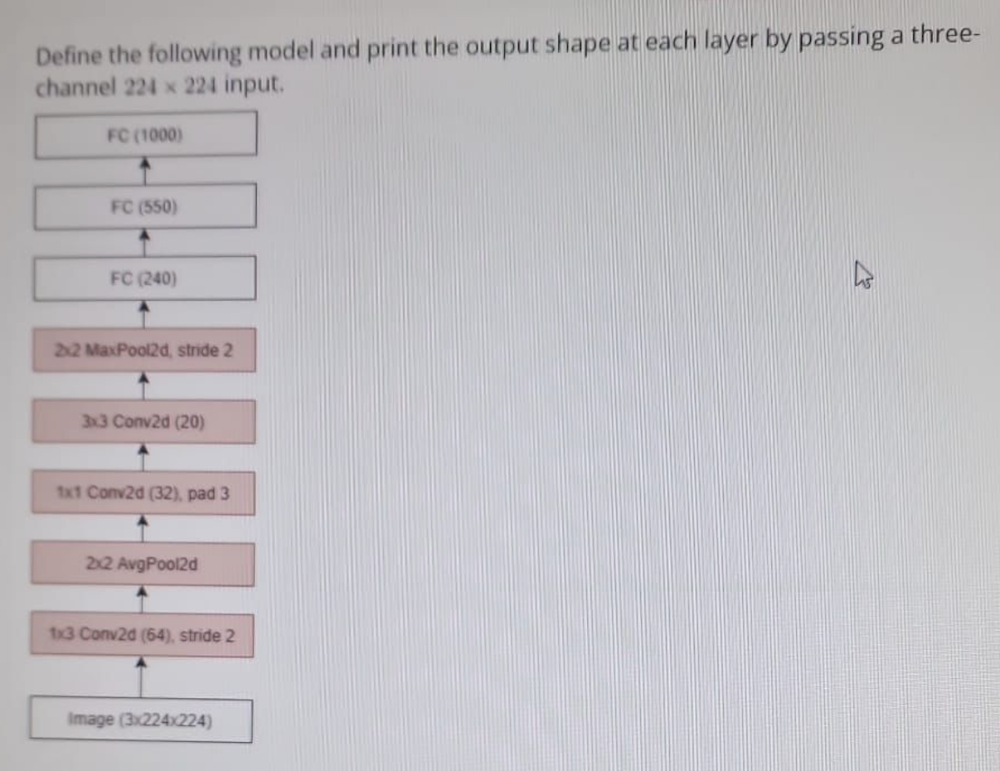

In [ ]:
import torch
import torch.nn as nn


class CustomNet(nn.Module):
    def __init__(self):
        super(CustomNet, self).__init__()

        # 1. 1x3 Conv2d (64), stride 2
        # Input: [B, 3, 224, 224]
        # We interpret '1x3' literally as kernel_size=(1, 3)
        self.conv1 = nn.Conv2d(
            in_channels=3, out_channels=64, kernel_size=(1, 3), stride=2
        )

        # 2. 2x2 AvgPool2d
        # Default stride for pooling is usually the kernel size (2)
        self.avgpool = nn.AvgPool2d(kernel_size=2)

        # 3. 1x1 Conv2d (32), pad 3
        # Padding increases the spatial dimensions here since kernel is 1x1
        self.conv2 = nn.Conv2d(
            in_channels=64, out_channels=32, kernel_size=1, padding=3
        )

        # 4. 3x3 Conv2d (20)
        # No stride/pad specified -> stride=1, padding=0
        self.conv3 = nn.Conv2d(in_channels=32, out_channels=20, kernel_size=3)

        # 5. 2x2 MaxPool2d, stride 2
        self.maxpool = nn.MaxPool2d(kernel_size=2, stride=2)

        # 6. Flatten
        self.flatten = nn.Flatten()

        # Calculating Linear Input Size:
        # Based on manual calculation (traced below), the output before flattening
        # is [B, 20, 30, 29].
        # 20 * 30 * 29 = 17400
        self.fc1 = nn.Linear(17400, 240)

        # 7. FC (550)
        self.fc2 = nn.Linear(240, 550)

        # 8. FC (1000)
        self.fc3 = nn.Linear(550, 1000)

    def forward(self, x):
        print(f"Input: {x.shape}")

        x = self.conv1(x)
        print(f"After 1x3 Conv: {x.shape}")

        x = self.avgpool(x)
        print(f"After AvgPool: {x.shape}")

        x = self.conv2(x)
        print(f"After 1x1 Conv (pad 3): {x.shape}")

        x = self.conv3(x)
        print(f"After 3x3 Conv: {x.shape}")

        x = self.maxpool(x)
        print(f"After MaxPool: {x.shape}")

        x = self.flatten(x)
        print(f"After Flatten: {x.shape}")

        x = self.fc1(x)
        print(f"After FC(240): {x.shape}")

        x = self.fc2(x)
        print(f"After FC(550): {x.shape}")

        x = self.fc3(x)
        print(f"After FC(1000): {x.shape}")

        return x


# Create the model
net = CustomNet()

# Create a dummy input tensor of shape 3x224x224 (Batch size 1)
input_tensor = torch.randn(1, 3, 224, 224)

# Run the model to print shapes
output = net(input_tensor)

Input: torch.Size([1, 3, 224, 224])
After 1x3 Conv: torch.Size([1, 64, 112, 111])
After AvgPool: torch.Size([1, 64, 56, 55])
After 1x1 Conv (pad 3): torch.Size([1, 32, 62, 61])
After 3x3 Conv: torch.Size([1, 20, 60, 59])
After MaxPool: torch.Size([1, 20, 30, 29])
After Flatten: torch.Size([1, 17400])
After FC(240): torch.Size([1, 240])
After FC(550): torch.Size([1, 550])
After FC(1000): torch.Size([1, 1000])


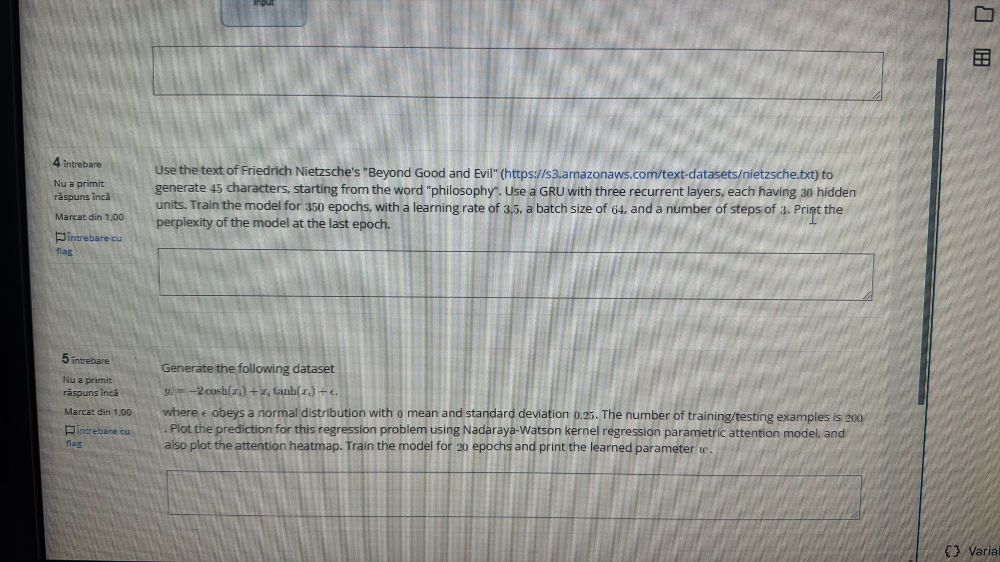

In [ ]:
import hashlib
import os
import requests
import re
import collections
import random
import torch
from torch import nn
from torch.nn import functional as F
import math
import matplotlib.pyplot as plt
import zipfile

torch.manual_seed(42)

In [ ]:
def download(url, cache_dir=os.path.join("..", "data")):
    """Download a file, return the local filename."""
    os.makedirs(cache_dir, exist_ok=True)
    fname = os.path.join(cache_dir, url.split("/")[-1])
    if os.path.exists(fname):
        with open(fname, "rb") as f:
            while True:
                data = f.read(1048576)
                if not data:
                    break
        return fname
    print(f"Downloading {fname} from {url}...")
    r = requests.get(url, stream=True, verify=True)
    with open(fname, "wb") as f:
        f.write(r.content)
    return fname

In [ ]:
def read_book():
    """Load the time machine dataset into a list of text lines."""
    with open(
        download("http://s3.amazonaws.com/text-datasets/nietzsche.txt"), "r"
    ) as f:
        lines = f.readlines()
    return [re.sub("[^A-Za-z]+", " ", line).strip().lower() for line in lines]


lines = read_book()
print(f"# text lines: {len(lines)}")
print(lines[0])
print(lines[10])

# text lines: 9935
preface
indeed it stands at all for there are scoffers who maintain that it


In [ ]:
def tokenize(lines, token="word"):
    """Split text lines into word or character tokens."""
    if token == "word":
        return [line.split() for line in lines]
    elif token == "char":
        return [list(line) for line in lines]
    else:
        print("ERROR: unknown token type: " + token)


tokens = tokenize(lines)
for i in range(11):
    print(tokens[i])

['preface']
[]
[]
['supposing', 'that', 'truth', 'is', 'a', 'woman', 'what', 'then', 'is', 'there', 'not', 'ground']
['for', 'suspecting', 'that', 'all', 'philosophers', 'in', 'so', 'far', 'as', 'they', 'have', 'been']
['dogmatists', 'have', 'failed', 'to', 'understand', 'women', 'that', 'the', 'terrible']
['seriousness', 'and', 'clumsy', 'importunity', 'with', 'which', 'they', 'have', 'usually', 'paid']
['their', 'addresses', 'to', 'truth', 'have', 'been', 'unskilled', 'and', 'unseemly', 'methods', 'for']
['winning', 'a', 'woman', 'certainly', 'she', 'has', 'never', 'allowed', 'herself', 'to', 'be', 'won', 'and']
['at', 'present', 'every', 'kind', 'of', 'dogma', 'stands', 'with', 'sad', 'and', 'discouraged', 'mien', 'if']
['indeed', 'it', 'stands', 'at', 'all', 'for', 'there', 'are', 'scoffers', 'who', 'maintain', 'that', 'it']


In [ ]:
class Vocab:
    """Vocabulary for text."""

    def __init__(self, tokens=None, min_freq=0, reserved_tokens=None):
        if tokens is None:
            tokens = []
        if reserved_tokens is None:
            reserved_tokens = []
        # Sort according to frequencies
        counter = count_corpus(tokens)
        self._token_freqs = sorted(counter.items(), key=lambda x: x[1], reverse=True)
        # The index for the unknown token is 0
        self.idx_to_token = ["<unk>"] + reserved_tokens
        self.token_to_idx = {token: idx for idx, token in enumerate(self.idx_to_token)}
        for token, freq in self._token_freqs:
            if freq < min_freq:
                break
            if token not in self.token_to_idx:
                self.idx_to_token.append(token)
                self.token_to_idx[token] = len(self.idx_to_token) - 1

    def __len__(self):
        return len(self.idx_to_token)

    def __getitem__(self, tokens):
        if not isinstance(tokens, (list, tuple)):
            return self.token_to_idx.get(tokens, self.unk)
        return [self.__getitem__(token) for token in tokens]

    def to_tokens(self, indices):
        if not isinstance(indices, (list, tuple)):
            return self.idx_to_token[indices]
        return [self.idx_to_token[index] for index in indices]

    @property
    def unk(self):  # Index for the unknown token
        return 0

    @property
    def token_freqs(self):  # Token frequencies
        return self._token_freqs


def count_corpus(tokens):
    """Count token frequencies."""
    # Here `tokens` is a 1D list or 2D list
    if len(tokens) == 0 or isinstance(tokens[0], list):
        # Flatten a list of token lists into a list of tokens
        tokens = [token for line in tokens for token in line]
    return collections.Counter(tokens)

In [ ]:
def load_corpus_book(max_tokens=-1):
    """Return token indices and the vocabulary of the time machine dataset."""
    lines = read_book()
    tokens = tokenize(lines, "char")
    vocab = Vocab(tokens)
    # Since each text line in the time machine dataset is not necessarily a
    # sentence or a paragraph, flatten all the text lines into a single list
    corpus = [vocab[token] for line in tokens for token in line]
    if max_tokens > 0:
        corpus = corpus[:max_tokens]
    return corpus, vocab


corpus, vocab = load_corpus_book()
len(corpus), len(vocab)

(570394, 28)

In [ ]:
def seq_data_iter_sequential(corpus, batch_size, num_steps):
    """Generate a mini-batch of subsequences using sequential partitioning."""
    # Start with a random offset to partition a sequence
    offset = random.randint(0, num_steps)
    num_tokens = ((len(corpus) - offset - 1) // batch_size) * batch_size
    Xs = torch.tensor(corpus[offset : offset + num_tokens])
    Ys = torch.tensor(corpus[offset + 1 : offset + 1 + num_tokens])
    Xs, Ys = Xs.reshape(batch_size, -1), Ys.reshape(batch_size, -1)
    num_batches = Xs.shape[1] // num_steps
    for i in range(0, num_steps * num_batches, num_steps):
        X = Xs[:, i : i + num_steps]
        Y = Ys[:, i : i + num_steps]
        yield X, Y

In [ ]:
class SeqDataLoader:
    """An iterator to load sequence data."""

    def __init__(self, batch_size, num_steps, max_tokens):
        self.corpus, self.vocab = load_corpus_book(max_tokens)
        self.batch_size, self.num_steps = batch_size, num_steps

    def __iter__(self):
        return seq_data_iter_sequential(self.corpus, self.batch_size, self.num_steps)

In [ ]:
def load_data_book(batch_size, num_steps, max_tokens=10000):
    """Return the iterator and the vocabulary of the time machine dataset."""
    data_iter = SeqDataLoader(batch_size, num_steps, max_tokens)
    return data_iter, data_iter.vocab

In [ ]:
# training data
batch_size, num_steps = 64, 3
train_iter, vocab = load_data_book(batch_size, num_steps)

In [ ]:
num_hiddens = 30
rnn_layer = nn.GRU(len(vocab), num_hiddens, num_layers=3)

In [ ]:
class RNNModel(nn.Module):
    """The RNN model."""

    def __init__(self, rnn_layer, vocab_size, **kwargs):
        super(RNNModel, self).__init__(**kwargs)
        self.rnn = rnn_layer
        self.vocab_size = vocab_size
        self.num_hiddens = self.rnn.hidden_size
        self.linear = nn.Linear(self.num_hiddens, self.vocab_size)

    def forward(self, inputs, state):
        X = F.one_hot(inputs.T.long(), self.vocab_size)
        X = X.to(torch.float32)
        Y, state = self.rnn(X, state)
        # The fully connected layer will first change the shape of `Y` to
        # (`num_steps` * `batch_size`, `num_hiddens`). Its output shape is
        # (`num_steps` * `batch_size`, `vocab_size`).
        output = self.linear(Y.reshape((-1, Y.shape[-1])))
        return output, state

    def begin_state(self, device, batch_size=1):
        if not isinstance(self.rnn, nn.LSTM):
            # `nn.GRU` takes a tensor as hidden state
            return torch.zeros(
                (self.rnn.num_layers, batch_size, self.num_hiddens), device=device
            )
        else:
            # `nn.LSTM` takes a tuple of hidden states
            return (
                torch.zeros(
                    (self.rnn.num_layers, batch_size, self.num_hiddens), device=device
                ),
                torch.zeros(
                    (self.rnn.num_layers, batch_size, self.num_hiddens), device=device
                ),
            )

In [ ]:
def try_gpu(i=0):
    """Return gpu(i) if exists, otherwise return cpu()."""
    if torch.cuda.device_count() >= i + 1:
        return torch.device(f"cuda:{i}")
    return torch.device("cpu")

In [ ]:
def predict(prefix, num_preds, net, vocab, device):
    """Generate new characters following the `prefix`."""
    state = net.begin_state(batch_size=1, device=device)
    outputs = [vocab[prefix[0]]]
    get_input = lambda: torch.tensor([outputs[-1]], device=device).reshape((1, 1))
    for y in prefix[1:]:  # Warm-up period
        _, state = net(get_input(), state)
        outputs.append(vocab[y])
    for _ in range(num_preds):  # Predict `num_preds` steps
        y, state = net(get_input(), state)
        outputs.append(int(y.argmax(dim=1).reshape(1)))
    return "".join([vocab.idx_to_token[i] for i in outputs])

In [ ]:
device = try_gpu()
net = RNNModel(rnn_layer, vocab_size=len(vocab))
net = net.to(device)
predict("traveller", 20, net, vocab, device)

'travellerhhhhssssssssssssssss'

In [ ]:
def grad_clipping(net, theta):
    """Clip the gradient."""
    params = [p for p in net.parameters() if p.requires_grad]
    norm = torch.sqrt(sum(torch.sum((p.grad**2)) for p in params))
    if norm > theta:
        for param in params:
            param.grad[:] *= theta / norm

In [ ]:
def train_epoch(net, train_iter, loss, optimizer, device):
    """Train a net within one epoch."""
    state = None
    # Sum of training loss, no. of tokens
    total_loss = 0
    total_tokens = 0
    for X, Y in train_iter:
        if state is None:
            # Initialize `state` when it is the first iteration
            state = net.begin_state(batch_size=X.shape[0], device=device)
        else:
            if not isinstance(state, tuple):
                # `state` is a tensor for `nn.GRU`
                state.detach_()
            else:
                # `state` is a tuple of tensors for `nn.LSTM`
                for s in state:
                    s.detach_()
        y = Y.T.reshape(-1)
        X, y = X.to(device), y.to(device)
        y_hat, state = net(X, state)
        l = loss(y_hat, y.long()).mean()
        optimizer.zero_grad()
        l.backward()
        grad_clipping(net, 1)
        optimizer.step()
        total_loss += float(l * y.numel())
        total_tokens += y.numel()
    return math.exp(total_loss / total_tokens)

In [ ]:
def train(net, train_iter, vocab, lr, num_epochs, device):
    """Train a model."""
    loss = nn.CrossEntropyLoss()
    perplexities = []
    # Initialize
    optimizer = torch.optim.SGD(net.parameters(), lr)
    # Train and predict
    for epoch in range(num_epochs):
        ppl = train_epoch(net, train_iter, loss, optimizer, device)
        if (epoch + 1) % 10 == 0:
            print(predict("philosophy", 45, net, vocab, device))  # changes
            perplexities.append(ppl)
    print(f"perplexity {ppl:.1f}, device {str(device)}")
    # print(predict('traveller', 20, net, vocab, device))           # changes
    # print(predict('traveller', 20, net, vocab, device))           # changes

    return perplexities

In [ ]:
num_epochs, lr = 350, 3.5
perplexities = train(net, train_iter, vocab, lr, num_epochs, device)  # 1 min

philosophyr it so hat has as it we hast be for the secr
philosophy has been been been been been been been been 
philosophy have bow it is so earderiously be belief the
philosophy it is it is it is it is it is it is it is it
philosophy it it it it it it it it it it it it it it it
philosophy in the strues of it who speak it which it wh
philosophy is is it it is is is is is is is is is is is
philosophy is ispressecordogessest is is is is is is is
philosophysions is all the seconss some it we in the se
philosophysopherselver or in the seconde of the seconde
philosophy it is is is is is is is is is is is is is is
philosophy it some be could it is wreally it stillentar
philosophy it sely us it is is is be in exert it is it 
philosophy is will to the stre us have by the sely in t
philosophy is will belief it be in the stheses the will
philosophy it it is the sely the sely the sely the sely
philosophy which or the secong origin of the secong ori
philosophy it is not have be the warro is which 

In [ ]:
def plot_perplexity(perplexities):
    epochs = range(10, len(perplexities * 10) + 1, 10)
    plt.plot(epochs, perplexities, "b", label="Train perplexity")
    plt.title("Training perplexity")
    plt.xlabel("Epochs")
    plt.ylabel("Perplexity")
    plt.legend()
    plt.show()

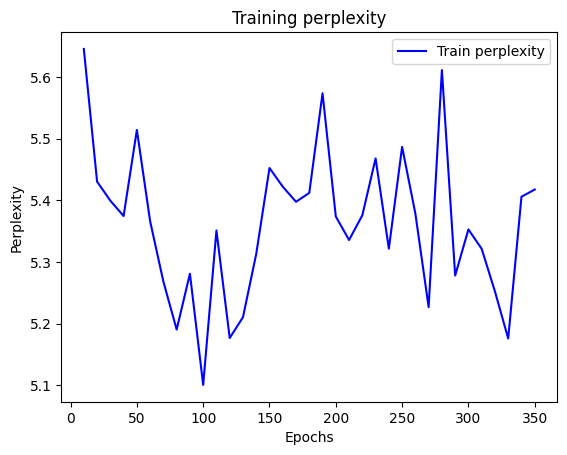

In [ ]:
plot_perplexity(perplexities)

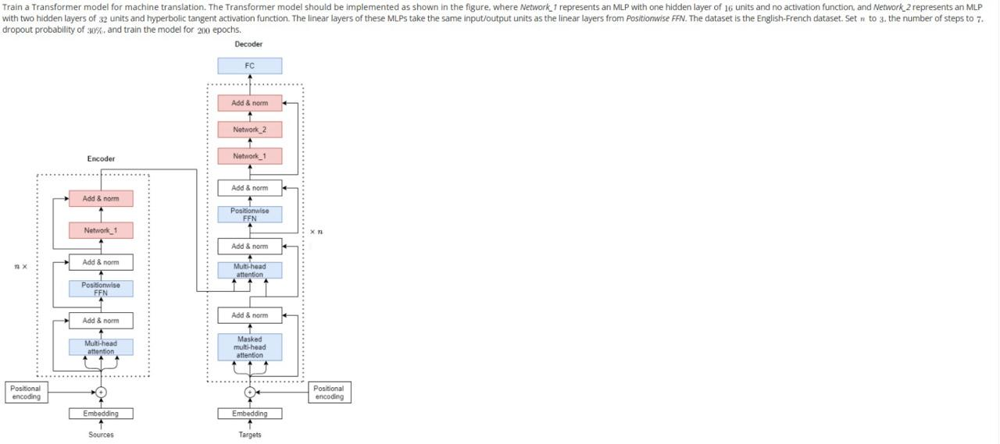

In [38]:
import torch
from torch import nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import math
import os
import requests
import zipfile
import collections

torch.manual_seed(42)

In [39]:
def sequence_mask(X, valid_len, value=0):
    """Mask irrelevant entries in sequences."""
    maxlen = X.size(1)
    mask = (
        torch.arange((maxlen), dtype=torch.float32, device=X.device)[None, :]
        < valid_len[:, None]
    )
    X[~mask] = value
    return X

In [40]:
def masked_softmax(X, valid_lens):
    """Perform softmax operation by masking elements on the last axis."""
    # `X`: 3D tensor, `valid_lens`: 1D or 2D tensor
    if valid_lens is None:
        return nn.functional.softmax(X, dim=-1)
    else:
        shape = X.shape
        if valid_lens.dim() == 1:
            valid_lens = torch.repeat_interleave(valid_lens, shape[1])
        else:
            valid_lens = valid_lens.reshape(-1)
        # On the last axis, replace masked elements with a very large negative
        # value, whose exponentiation outputs 0
        X = sequence_mask(X.reshape(-1, shape[-1]), valid_lens, value=-1e6)
        return F.softmax(X.reshape(shape), dim=-1)

In [41]:
class DotProductAttention(nn.Module):
    """Scaled dot product attention."""

    def __init__(self, dropout, **kwargs):
        super(DotProductAttention, self).__init__(**kwargs)
        self.dropout = nn.Dropout(dropout)

    # Shape of `queries` is: (`batch_size`, no. of queries, `d`)
    # Shape of `keys` is: (`batch_size`, no. of key-value pairs, `d`)
    # Shape of `values` is: (`batch_size`, no. of key-value pairs, value
    # dimension)
    # Shape of `valid_lens`: (`batch_size`,) or (`batch_size`, no. of queries)
    def forward(self, queries, keys, values, valid_lens=None):
        d = queries.shape[-1]
        # Use `keys.transpose(1,2)` to swap the last two dimensions of `keys`
        scores = torch.bmm(queries, keys.transpose(1, 2)) / math.sqrt(d)
        self.attention_weights = masked_softmax(scores, valid_lens)
        return torch.bmm(self.dropout(self.attention_weights), values)

In [42]:
def transpose_qkv(X, num_heads):
    """Transposition for parallel computation of multiple attention heads."""
    # Shape of input `X` is:
    # (`batch_size`, no. of queries or key-value pairs, `num_hiddens`).
    # Shape of output `X` is:
    # (`batch_size`, no. of queries or key-value pairs, `num_heads`,
    # `num_hiddens` / `num_heads`)
    X = X.reshape(X.shape[0], X.shape[1], num_heads, -1)

    # Shape of output `X` is:
    # (`batch_size`, `num_heads`, no. of queries or key-value pairs,
    # `num_hiddens` / `num_heads`)
    X = X.permute(0, 2, 1, 3)

    # Shape of `output` is:
    # (`batch_size` * `num_heads`, no. of queries or key-value pairs,
    # `num_hiddens` / `num_heads`)
    return X.reshape(-1, X.shape[2], X.shape[3])


def transpose_output(X, num_heads):
    """Reverse the operation of `transpose_qkv`."""
    X = X.reshape(-1, num_heads, X.shape[1], X.shape[2])
    X = X.permute(0, 2, 1, 3)
    return X.reshape(X.shape[0], X.shape[1], -1)

In [43]:
class MultiHeadAttention(nn.Module):
    """Multi-head attention."""

    def __init__(
        self,
        key_size,
        query_size,
        value_size,
        num_hiddens,
        num_heads,
        dropout,
        bias=False,
        **kwargs
    ):
        super(MultiHeadAttention, self).__init__(**kwargs)
        self.num_heads = num_heads
        self.attention = DotProductAttention(dropout)
        self.W_q = nn.Linear(query_size, num_hiddens, bias=bias)
        self.W_k = nn.Linear(key_size, num_hiddens, bias=bias)
        self.W_v = nn.Linear(value_size, num_hiddens, bias=bias)
        self.W_o = nn.Linear(num_hiddens, num_hiddens, bias=bias)

    def forward(self, queries, keys, values, valid_lens):
        # Shape of `queries`, `keys`, or `values` is:
        # (`batch_size`, no. of queries or key-value pairs, `num_hiddens`)
        # Shape of `valid_lens` is:
        # (`batch_size`,) or (`batch_size`, no. of queries)
        # After transposing, shape of output `queries`, `keys`, or `values` is:
        # (`batch_size` * `num_heads`, no. of queries or key-value pairs,
        # `num_hiddens` / `num_heads`)
        queries = transpose_qkv(self.W_q(queries), self.num_heads)
        keys = transpose_qkv(self.W_k(keys), self.num_heads)
        values = transpose_qkv(self.W_v(values), self.num_heads)

        if valid_lens is not None:
            # On axis 0, copy the first item (scalar or vector) for
            # `num_heads` times, then copy the next item, and so on
            valid_lens = torch.repeat_interleave(
                valid_lens, repeats=self.num_heads, dim=0
            )

        # Shape of `output` is: (`batch_size` * `num_heads`, no. of queries,
        # `num_hiddens` / `num_heads`)
        output = self.attention(queries, keys, values, valid_lens)

        # Shape of `output_concat` is:
        # (`batch_size`, no. of queries, `num_hiddens`)
        output_concat = transpose_output(output, self.num_heads)
        return self.W_o(output_concat)

In [44]:
class PositionalEncoding(nn.Module):
    """Positional encoding."""

    def __init__(self, num_hiddens, dropout, max_len=1000):
        super(PositionalEncoding, self).__init__()
        self.dropout = nn.Dropout(dropout)
        # Create a long enough `P`
        self.P = torch.zeros((1, max_len, num_hiddens))
        X = torch.arange(max_len, dtype=torch.float32).reshape(-1, 1) / torch.pow(
            10000, torch.arange(0, num_hiddens, 2, dtype=torch.float32) / num_hiddens
        )
        self.P[:, :, 0::2] = torch.sin(X)
        self.P[:, :, 1::2] = torch.cos(X)

    def forward(self, X):
        X = X + self.P[:, : X.shape[1], :].to(X.device)
        return self.dropout(X)

In [45]:
class AddNorm(nn.Module):
    """Residual connection followed by layer normalization."""

    def __init__(self, normalized_shape, dropout, **kwargs):
        super(AddNorm, self).__init__(**kwargs)
        self.dropout = nn.Dropout(dropout)
        self.ln = nn.LayerNorm(normalized_shape)

    def forward(self, X, Y):
        return self.ln(self.dropout(Y) + X)

In [46]:
class PositionWiseFFN(nn.Module):
    """Position-wise feed-forward network."""

    def __init__(self, ffn_num_input, ffn_num_hiddens, ffn_num_outputs, **kwargs):
        super(PositionWiseFFN, self).__init__(**kwargs)
        self.dense1 = nn.Linear(ffn_num_input, ffn_num_hiddens)
        self.dense2 = nn.Linear(ffn_num_hiddens, ffn_num_hiddens)
        self.dense3 = nn.Linear(ffn_num_hiddens, ffn_num_hiddens)

        self.relu = nn.ReLU()

        self.dense4 = nn.Linear(ffn_num_hiddens, ffn_num_outputs)

    def forward(self, X):
        return self.dense4(self.relu(self.dense3(self.dense2(self.dense1(X)))))

In [47]:
class Network_1(nn.Module):
    """Network_1: MLP with one hidden layer of 16 units and no activation function."""

    def __init__(self, num_hiddens, **kwargs):
        super(Network_1, self).__init__(**kwargs)
        # Input/output units match PositionWiseFFN (num_hiddens)
        # Hidden layer: 16 units, no activation function
        self.dense1 = nn.Linear(num_hiddens, 16)
        self.dense2 = nn.Linear(16, num_hiddens)

    def forward(self, X):
        # No activation function - just linear transformations
        return self.dense2(self.dense1(X))

In [48]:
class Network_2(nn.Module):
    """Network_2: MLP with two hidden layers of 32 units and tanh activation function."""

    def __init__(self, num_hiddens, **kwargs):
        super(Network_2, self).__init__(**kwargs)
        # Input/output units match PositionWiseFFN (num_hiddens)
        # Two hidden layers of 32 units with tanh activation
        self.dense1 = nn.Linear(num_hiddens, 32)
        self.dense2 = nn.Linear(32, 32)
        self.dense3 = nn.Linear(32, num_hiddens)
        self.tanh = nn.Tanh()

    def forward(self, X):
        # Two hidden layers with tanh activation
        X = self.tanh(self.dense1(X))
        X = self.tanh(self.dense2(X))
        return self.dense3(X)

In [49]:
class Encoder(nn.Module):
    """The base encoder interface for the encoder-decoder architecture."""

    def __init__(self, **kwargs):
        super(Encoder, self).__init__(**kwargs)

    def forward(self, X, *args):
        raise NotImplementedError

In [50]:
class EncoderBlock(nn.Module):
    """Transformer encoder block."""

    def __init__(
        self,
        key_size,
        query_size,
        value_size,
        num_hiddens,
        norm_shape,
        ffn_num_input,
        ffn_num_hiddens,
        num_heads,
        dropout,
        use_bias=False,
        **kwargs
    ):
        super(EncoderBlock, self).__init__(**kwargs)
        self.attention = MultiHeadAttention(
            key_size, query_size, value_size, num_hiddens, num_heads, dropout, use_bias
        )
        self.addnorm1 = AddNorm(norm_shape, dropout)
        self.ffn = PositionWiseFFN(ffn_num_input, ffn_num_hiddens, num_hiddens)
        self.addnorm2 = AddNorm(norm_shape, dropout)
        self.network_1 = Network_1(num_hiddens)
        self.addnorm3 = AddNorm(norm_shape, dropout)

    def forward(self, X, valid_lens):
        Y = self.addnorm1(X, self.attention(X, X, X, valid_lens))
        Y = self.addnorm2(Y, self.ffn(Y))
        return self.addnorm3(Y, self.network_1(Y))

In [51]:
class TransformerEncoder(Encoder):
    """Transformer encoder."""

    def __init__(
        self,
        vocab_size,
        key_size,
        query_size,
        value_size,
        num_hiddens,
        norm_shape,
        ffn_num_input,
        ffn_num_hiddens,
        num_heads,
        num_layers,
        dropout,
        use_bias=False,
        **kwargs
    ):
        super(TransformerEncoder, self).__init__(**kwargs)
        self.num_hiddens = num_hiddens
        self.embedding = nn.Embedding(vocab_size, num_hiddens)
        self.pos_encoding = PositionalEncoding(num_hiddens, dropout)
        self.blks = nn.Sequential()
        for i in range(num_layers):
            self.blks.add_module(
                "block" + str(i),
                EncoderBlock(
                    key_size,
                    query_size,
                    value_size,
                    num_hiddens,
                    norm_shape,
                    ffn_num_input,
                    ffn_num_hiddens,
                    num_heads,
                    dropout,
                    use_bias,
                ),
            )

    def forward(self, X, valid_lens, *args):
        # Since positional encoding values are between -1 and 1, the embedding
        # values are multiplied by the square root of the embedding dimension
        # to rescale before they are summed up
        X = self.pos_encoding(self.embedding(X) * math.sqrt(self.num_hiddens))
        self.attention_weights = [None] * len(self.blks)
        for i, blk in enumerate(self.blks):
            X = blk(X, valid_lens)
            self.attention_weights[i] = blk.attention.attention.attention_weights
        return X

In [52]:
class Decoder(nn.Module):
    """The base decoder interface for the encoder-decoder architecture."""

    def __init__(self, **kwargs):
        super(Decoder, self).__init__(**kwargs)

    def init_state(self, enc_outputs, *args):
        raise NotImplementedError

    def forward(self, X, state):
        raise NotImplementedError

In [53]:
class AttentionDecoder(Decoder):
    """The base attention-based decoder interface."""

    def __init__(self, **kwargs):
        super(AttentionDecoder, self).__init__(**kwargs)

    @property
    def attention_weights(self):
        raise NotImplementedError

In [54]:
class DecoderBlock(nn.Module):
    # The `i`-th block in the decoder
    def __init__(
        self,
        key_size,
        query_size,
        value_size,
        num_hiddens,
        norm_shape,
        ffn_num_input,
        ffn_num_hiddens,
        num_heads,
        dropout,
        i,
        **kwargs
    ):
        super(DecoderBlock, self).__init__(**kwargs)
        self.i = i
        self.attention1 = MultiHeadAttention(
            key_size, query_size, value_size, num_hiddens, num_heads, dropout
        )
        self.addnorm1 = AddNorm(norm_shape, dropout)
        self.attention2 = MultiHeadAttention(
            key_size, query_size, value_size, num_hiddens, num_heads, dropout
        )
        self.addnorm2 = AddNorm(norm_shape, dropout)
        self.ffn = PositionWiseFFN(ffn_num_input, ffn_num_hiddens, num_hiddens)
        self.network_1 = Network_1(num_hiddens)
        self.network_2 = Network_2(num_hiddens)
        self.addnorm3 = AddNorm(norm_shape, dropout)

    def forward(self, X, state):
        enc_outputs, enc_valid_lens = state[0], state[1]
        # During training, all the tokens of any output sequence are processed
        # at the same time, so `state[2][self.i]` is `None` as initialized.
        # When decoding any output sequence token by token during prediction,
        # `state[2][self.i]` contains representations of the decoded output at
        # the `i`-th block up to the current time step
        if state[2][self.i] is None:
            key_values = X
        else:
            key_values = torch.cat((state[2][self.i], X), axis=1)
        state[2][self.i] = key_values
        if self.training:
            batch_size, num_steps, _ = X.shape
            # Shape of `dec_valid_lens` is: (`batch_size`, `num_steps`), where
            # every row is [1, 2, ..., `num_steps`]
            dec_valid_lens = torch.arange(1, num_steps + 1, device=X.device).repeat(
                batch_size, 1
            )
        else:
            dec_valid_lens = None

        # Self-attention
        X2 = self.attention1(X, key_values, key_values, dec_valid_lens)
        Y = self.addnorm1(X, X2)
        # Encoder-decoder attention. Shape of `enc_outputs` is:
        # (`batch_size`, `num_steps`, `num_hiddens`)
        Y2 = self.attention2(Y, enc_outputs, enc_outputs, enc_valid_lens)
        Z = self.addnorm2(Y, Y2)
        # Positionwise FFN with Network_1 and Network_2 sequentially
        Z_ffn = self.ffn(Z)
        Z_n1 = self.network_1(Z_ffn)
        Z_n2 = self.network_2(Z_n1)
        return self.addnorm3(Z, Z_n2), state

In [55]:
class TransformerDecoder(AttentionDecoder):
    def __init__(
        self,
        vocab_size,
        key_size,
        query_size,
        value_size,
        num_hiddens,
        norm_shape,
        ffn_num_input,
        ffn_num_hiddens,
        num_heads,
        num_layers,
        dropout,
        **kwargs
    ):
        super(TransformerDecoder, self).__init__(**kwargs)
        self.num_hiddens = num_hiddens
        self.num_layers = num_layers
        self.embedding = nn.Embedding(vocab_size, num_hiddens)
        self.pos_encoding = PositionalEncoding(num_hiddens, dropout)
        self.blks = nn.Sequential()
        for i in range(num_layers):
            self.blks.add_module(
                "block" + str(i),
                DecoderBlock(
                    key_size,
                    query_size,
                    value_size,
                    num_hiddens,
                    norm_shape,
                    ffn_num_input,
                    ffn_num_hiddens,
                    num_heads,
                    dropout,
                    i,
                ),
            )
        self.dense = nn.Linear(num_hiddens, vocab_size)

    def init_state(self, enc_outputs, enc_valid_lens, *args):
        return [enc_outputs, enc_valid_lens, [None] * self.num_layers]

    def forward(self, X, state):
        X = self.pos_encoding(self.embedding(X) * math.sqrt(self.num_hiddens))
        self._attention_weights = [[None] * len(self.blks) for _ in range(2)]
        for i, blk in enumerate(self.blks):
            X, state = blk(X, state)
            # Decoder self-attention weights
            self._attention_weights[0][i] = blk.attention1.attention.attention_weights
            # Encoder-decoder attention weights
            self._attention_weights[1][i] = blk.attention2.attention.attention_weights
        return self.dense(X), state

    @property
    def attention_weights(self):
        return self._attention_weights

In [56]:
class EncoderDecoder(nn.Module):
    """The base class for the encoder-decoder architecture."""

    def __init__(self, encoder, decoder, **kwargs):
        super(EncoderDecoder, self).__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder

    def forward(self, enc_X, dec_X, *args):
        enc_outputs = self.encoder(enc_X, *args)
        dec_state = self.decoder.init_state(enc_outputs, *args)
        return self.decoder(dec_X, dec_state)

In [57]:
def try_gpu(i=0):
    """Return gpu(i) if exists, otherwise return cpu()."""
    if torch.cuda.device_count() >= i + 1:
        return torch.device(f"cuda:{i}")
    return torch.device("cpu")

In [58]:
class Vocab:
    """Vocabulary for text."""

    def __init__(self, tokens=None, min_freq=0, reserved_tokens=None):
        if tokens is None:
            tokens = []
        if reserved_tokens is None:
            reserved_tokens = []
        # Sort according to frequencies
        counter = count_corpus(tokens)
        self._token_freqs = sorted(counter.items(), key=lambda x: x[1], reverse=True)
        # The index for the unknown token is 0
        self.idx_to_token = ["<unk>"] + reserved_tokens
        self.token_to_idx = {token: idx for idx, token in enumerate(self.idx_to_token)}
        for token, freq in self._token_freqs:
            if freq < min_freq:
                break
            if token not in self.token_to_idx:
                self.idx_to_token.append(token)
                self.token_to_idx[token] = len(self.idx_to_token) - 1

    def __len__(self):
        return len(self.idx_to_token)

    def __getitem__(self, tokens):
        if not isinstance(tokens, (list, tuple)):
            return self.token_to_idx.get(tokens, self.unk)
        return [self.__getitem__(token) for token in tokens]

    def to_tokens(self, indices):
        if not isinstance(indices, (list, tuple)):
            return self.idx_to_token[indices]
        return [self.idx_to_token[index] for index in indices]

    @property
    def unk(self):  # Index for the unknown token
        return 0

    @property
    def token_freqs(self):  # Token frequencies
        return self._token_freqs


def count_corpus(tokens):
    """Count token frequencies."""
    # Here `tokens` is a 1D list or 2D list
    if len(tokens) == 0 or isinstance(tokens[0], list):
        # Flatten a list of token lists into a list of tokens
        tokens = [token for line in tokens for token in line]
    return collections.Counter(tokens)


def download(url, cache_dir=os.path.join("..", "data")):
    """Download a file, return the local filename."""
    os.makedirs(cache_dir, exist_ok=True)
    fname = os.path.join(cache_dir, url.split("/")[-1])
    if os.path.exists(fname):
        with open(fname, "rb") as f:
            while True:
                data = f.read(1048576)
                if not data:
                    break
        return fname
    print(f"Downloading {fname} from {url}...")
    r = requests.get(url, stream=True, verify=True)
    with open(fname, "wb") as f:
        f.write(r.content)
    return fname


def download_extract(url, folder=None):
    """Download and extract a zip file."""
    fname = download(url)
    base_dir = os.path.dirname(fname)
    data_dir, ext = os.path.splitext(fname)
    if ext == ".zip":
        fp = zipfile.ZipFile(fname, "r")
    else:
        assert False, "Only zip files can be extracted."
    fp.extractall(base_dir)
    return os.path.join(base_dir, folder) if folder else data_dir


def read_data_nmt():
    """Load the English-French dataset."""
    data_dir = download_extract(
        "http://d2l-data.s3-accelerate.amazonaws.com/fra-eng.zip"
    )
    with open(os.path.join(data_dir, "fra.txt"), "r") as f:
        return f.read()


def preprocess_nmt(text):
    """Preprocess the English-French dataset."""

    def no_space(char, prev_char):
        return char in set(",.!?") and prev_char != " "

    # Replace non-breaking space with space, and convert uppercase letters to
    # lowercase ones
    text = text.replace("\u202f", " ").replace("\xa0", " ").lower()
    # Insert space between words and punctuation marks
    out = [
        " " + char if i > 0 and no_space(char, text[i - 1]) else char
        for i, char in enumerate(text)
    ]
    return "".join(out)


def tokenize_nmt(text, num_examples=None):
    """Tokenize the English-French dataset."""
    source, target = [], []
    for i, line in enumerate(text.split("\n")):
        if num_examples and i > num_examples:
            break
        parts = line.split("\t")
        if len(parts) == 2:
            source.append(parts[0].split(" "))
            target.append(parts[1].split(" "))
    return source, target


def truncate_pad(line, num_steps, padding_token):
    """Truncate or pad sequences."""
    if len(line) > num_steps:
        return line[:num_steps]  # Truncate
    return line + [padding_token] * (num_steps - len(line))  # Pad


def build_array_nmt(lines, vocab, num_steps):
    """Transform text sequences of machine translation into mini-batches."""
    lines = [vocab[l] for l in lines]
    lines = [l + [vocab["<eos>"]] for l in lines]
    array = torch.tensor([truncate_pad(l, num_steps, vocab["<pad>"]) for l in lines])
    valid_len = (array != vocab["<pad>"]).type(torch.int32).sum(1)
    return array, valid_len


def load_array(data_arrays, batch_size, is_train=True):
    """Construct a PyTorch data iterator."""
    dataset = torch.utils.data.TensorDataset(*data_arrays)
    return torch.utils.data.DataLoader(dataset, batch_size, shuffle=is_train)


def load_data_nmt(batch_size, num_steps, num_examples=600):
    """Return the iterator and the vocabularies of the translation dataset."""
    text = preprocess_nmt(read_data_nmt())
    source, target = tokenize_nmt(text, num_examples)
    src_vocab = Vocab(source, min_freq=2, reserved_tokens=["<pad>", "<bos>", "<eos>"])
    tgt_vocab = Vocab(target, min_freq=2, reserved_tokens=["<pad>", "<bos>", "<eos>"])
    src_array, src_valid_len = build_array_nmt(source, src_vocab, num_steps)
    tgt_array, tgt_valid_len = build_array_nmt(target, tgt_vocab, num_steps)
    data_arrays = (src_array, src_valid_len, tgt_array, tgt_valid_len)
    data_iter = load_array(data_arrays, batch_size)
    return data_iter, src_vocab, tgt_vocab

In [59]:
class MaskedSoftmaxCELoss(nn.CrossEntropyLoss):
    """The softmax cross-entropy loss with masks."""

    # `pred` shape: (`batch_size`, `num_steps`, `vocab_size`)
    # `label` shape: (`batch_size`, `num_steps`)
    # `valid_len` shape: (`batch_size`,)
    def forward(self, pred, label, valid_len):
        weights = torch.ones_like(label)
        weights = sequence_mask(weights, valid_len)
        self.reduction = "none"
        unweighted_loss = super(MaskedSoftmaxCELoss, self).forward(
            pred.permute(0, 2, 1), label
        )
        weighted_loss = (unweighted_loss * weights).mean(dim=1)
        return weighted_loss


def grad_clipping(net, theta):
    """Clip the gradient."""
    params = [p for p in net.parameters() if p.requires_grad]
    norm = torch.sqrt(sum(torch.sum((p.grad**2)) for p in params))
    if norm > theta:
        for param in params:
            param.grad[:] *= theta / norm


def train_seq2seq(net, data_iter, lr, num_epochs, tgt_vocab, device):
    """Train a model for sequence to sequence."""

    def xavier_init_weights(m):
        if type(m) == nn.Linear:
            nn.init.xavier_uniform_(m.weight)
        if type(m) == nn.GRU:
            for param in m._flat_weights_names:
                if "weight" in param:
                    nn.init.xavier_uniform_(m._parameters[param])

    net.apply(xavier_init_weights)
    net.to(device)
    optimizer = torch.optim.Adam(net.parameters(), lr=lr)
    loss = MaskedSoftmaxCELoss()
    net.train()
    train_loss_all = []
    for epoch in range(num_epochs):
        # Sum of training loss, no. of tokens
        total_loss = 0
        total_tokens = 0
        for batch in data_iter:
            optimizer.zero_grad()
            X, X_valid_len, Y, Y_valid_len = [x.to(device) for x in batch]
            bos = torch.tensor(
                [tgt_vocab["<bos>"]] * Y.shape[0], device=device
            ).reshape(-1, 1)
            dec_input = torch.cat([bos, Y[:, :-1]], 1)  # Teacher forcing
            Y_hat, _ = net(X, dec_input, X_valid_len)
            l = loss(Y_hat, Y, Y_valid_len)
            l.sum().backward()  # Make the loss scalar for `backward`
            grad_clipping(net, 1)
            num_tokens = Y_valid_len.sum()
            optimizer.step()
            with torch.no_grad():
                total_loss += l.sum()
                total_tokens += num_tokens
        if (epoch + 1) % 10 == 0:
            train_loss_all.append(total_loss / total_tokens)
    print(f"loss {total_loss / total_tokens:.3f}, device {str(device)}")

    return train_loss_all

In [60]:
num_hiddens, num_layers, dropout, batch_size, num_steps = 32, 2, 0.7, 64, 10
lr, num_epochs, device = 0.005, 400, try_gpu()
ffn_num_input, ffn_num_hiddens, num_heads = 32, 64, 4
key_size, query_size, value_size = 32, 32, 32
norm_shape = [32]

train_iter, src_vocab, tgt_vocab = load_data_nmt(batch_size, num_steps)

encoder = TransformerEncoder(
    len(src_vocab),
    key_size,
    query_size,
    value_size,
    num_hiddens,
    norm_shape,
    ffn_num_input,
    ffn_num_hiddens,
    num_heads,
    num_layers,
    dropout,
)
decoder = TransformerDecoder(
    len(tgt_vocab),
    key_size,
    query_size,
    value_size,
    num_hiddens,
    norm_shape,
    ffn_num_input,
    ffn_num_hiddens,
    num_heads,
    num_layers,
    dropout,
)
net = EncoderDecoder(encoder, decoder)
train_loss_all = train_seq2seq(
    net, train_iter, lr, num_epochs, tgt_vocab, device
)  # 1 min

loss 0.190, device cpu


In [61]:
def plot_loss(train_loss_all):
    epochs = range(10, len(train_loss_all * 10) + 1, 10)
    plt.plot(epochs, train_loss_all, "b", label="Train loss")
    plt.title("Training loss")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()

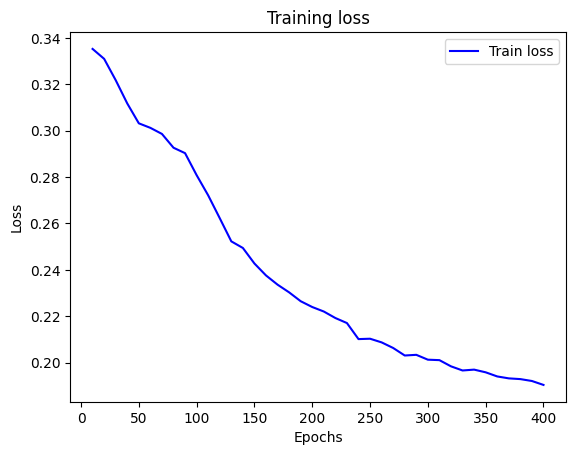

In [62]:
plot_loss(train_loss_all)